DSN -  SALES PREDICTION PROJECT

In [541]:
# Load Libraries
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from catboost import CatBoostRegressor
from sklearn.impute import SimpleImputer

import joblib
import pickle
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style='darkgrid')
pd.set_option('display.max_columns', None)


In [542]:
df = pd.read_csv("train.csv")
df.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


Exploring dataset information and attributes

In [543]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   object 
 1   product_code         6818 non-null   object 
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   object 
 4   shelf_visibility     6818 non-null   float64
 5   product_category     6818 non-null   object 
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   object 
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   object 
 10  store_location_tier  6818 non-null   object 
 11  store_format         6818 non-null   object 
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), object(8)
memory usage: 692.6+ KB


In [544]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
product_weight_kg,5593.0,12.850876,4.646542,4.482,8.7500,12.6470,16.8940,21.8830
shelf_visibility,6818.0,0.065527,0.051566,0.000,0.0266,0.0532,0.0934,0.3201
product_price,6818.0,140.473623,62.413513,31.110,93.2800,142.0650,185.9875,273.0400
store_age_years,6818.0,34.178205,8.384574,23.000,28.0000,33.0000,45.0000,47.0000
total_sales,6818.0,2174.756574,1697.894956,32.700,834.7925,1790.8900,3092.5875,12996.8200


In [545]:
# Cheking for missing data
df.isnull().sum()

id                        0
product_code              0
product_weight_kg      1225
fat_content               0
shelf_visibility          0
product_category          0
product_price             0
store_code                0
store_age_years           0
store_size             1919
store_location_tier       0
store_format              0
total_sales               0
dtype: int64

In [546]:
for c, v in enumerate(df.isnull().sum()):
    if v>0:
        print(f"{df.columns[c]} --> Missing Datapoints: {v}")

product_weight_kg --> Missing Datapoints: 1225
store_size --> Missing Datapoints: 1919


Two columns; (product weight and storesize have missing datapoints)

In [547]:
# Checking for duplicate
df.duplicated().sum()

np.int64(0)

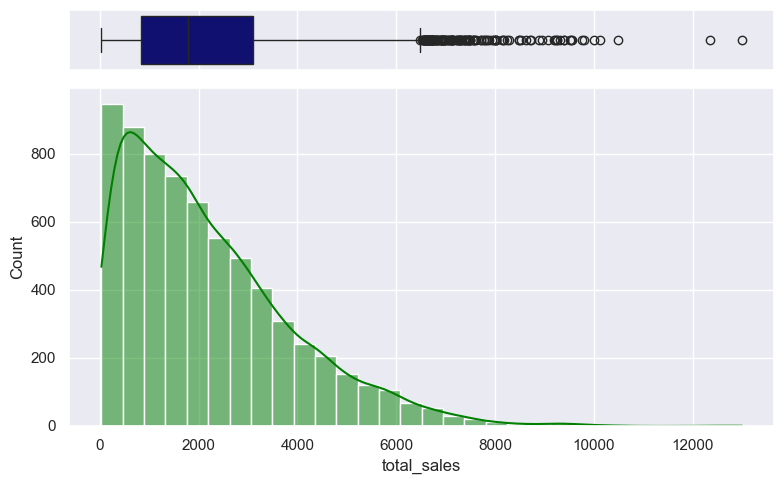

In [548]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, sharex=True, gridspec_kw={'height_ratios':(0.15, 0.85)}, figsize=(8, 5)
)

sns.boxplot(data=df, x='total_sales', ax=ax_box, color='Navy')
ax_box.set(xlabel='Total_Sales')

sns.histplot(data=df, x='total_sales', ax=ax_hist,color='green', kde=True, bins=30)
plt.tight_layout()
plt.show()

In [549]:
df['total_sales'].describe().T

count     6818.000000
mean      2174.756574
std       1697.894956
min         32.700000
25%        834.792500
50%       1790.890000
75%       3092.587500
max      12996.820000
Name: total_sales, dtype: float64

In [550]:
df_bycat = df.groupby('product_category').agg({'total_sales':['mean', 'median', 'std']})
df_bycat


total_sales                       
                              mean    median          std
product_category                                         
BAKING GOODS           2051.639781  1609.950  1652.284201
BREADS                 1853.545778  1600.750  1388.342458
BREAKFAST              1996.679474  1613.890  1867.514179
Baking Goods           1916.820039  1578.470  1524.017346
Breads                 2292.078000  1865.755  1749.512338
Breakfast              1827.852195  1423.570  1626.269921
CANNED                 2231.389915  1759.340  1813.745618
Canned                 2127.398229  1805.650  1555.753143
DAIRY                  2124.938671  1482.790  1748.955040
Dairy                  2226.652900  1781.820  1839.210384
FROZEN FOODS           2086.570988  1571.835  1720.593040
FRUITS AND VEGETABLES  2381.811379  1873.450  1856.298062
Frozen Foods           2142.175491  1701.720  1747.509740
Fruits and Vegetables  2193.589229  1696.790  1760.099423
HARD DRINKS            2100.019167  1855.490  1742.056064
HEALTH AND HYGIENE     2076.042525  1732.970  1449.965158
HOUSEHOLD              2294.584270  1990.840  1840.804827
Hard Drinks            2298.180978  1763.265  1713.784431
Health and Hygiene     2023.714975  1664.320  1629.343830
Household              2286.221344  2076.690  1653.284235
MEAT                   2159.563298  1823.275  1662.343388
Meat                   2372.897261  1883.860  1869.289999
OTHERS                 2079.960000  1866.970  1691.447698
Others                 1848.857671  1557.960  1500.175336
SEAFOOD                2212.578571  1485.085  2042.622930
SNACK FOODS            2179.350131  1943.620  1463.473820
SOFT DRINKS            1905.055500  1380.635  1509.307509
STARCHY FOODS          2419.785333  2049.325  1768.174333
Seafood                1956.157917  1995.245  1458.617630
Snack Foods            2259.235192  1815.620  1671.965482
Soft Drinks            2056.137697  1314.565  1928.778448
Starchy Foods          2404.877627  2037.090  1656.753099
baking goods           1878.849280  1522.480  1453.623849
breads                 2247.552037  1916.760  1528.431736
breakfast              1782.318400  1403.970  1517.681787
canned                 2309.617132  1894.880  1565.956903
dairy                  2374.590141  1796.840  1937.573686
frozen foods           2190.849831  1730.900  1811.978128
fruits and vegetables  2328.098868  1961.090  1760.319230
hard drinks            2025.119024  1850.300  1408.329594
health and hygiene     1881.565086  1605.460  1526.924633
household              2304.512500  1984.620  1740.378170
meat                   2182.470455  1811.690  1663.784926
others                 2061.644706  2005.110  1245.516625
seafood                2837.669286  2683.005  2166.050850
snack foods            2196.782500  1912.895  1700.582507
soft drinks            1858.751591  1423.830  1522.667450
starchy foods          2399.619167  1960.055  1961.053321

There are some inconsistencies detected in the poduct_category column.
- There are repeated products but appears in different sentence cases. 
- The model will recognise and treat them as different product

Now, we need to convert them to a consistent format. 

In [551]:
df["product_category"]=df["product_category"].apply(lambda x:x.capitalize())

df["product_category"].value_counts()

product_category
Fruits and vegetables    1006
Snack foods               933
Household                 740
Frozen foods              675
Dairy                     554
Canned                    517
Baking goods              516
Health and hygiene        412
Soft drinks               366
Meat                      339
Breads                    209
Hard drinks               169
Others                    132
Starchy foods             113
Breakfast                  85
Seafood                    52
Name: count, dtype: int64

In [552]:
for i in df["product_category"].unique():
    print(i)

Frozen foods
Health and hygiene
Canned
Soft drinks
Meat
Snack foods
Baking goods
Household
Dairy
Fruits and vegetables
Breakfast
Breads
Seafood
Others
Hard drinks
Starchy foods


In [553]:
df_bystoresize = df.groupby('store_size').agg({'total_sales':['mean', 'median', 'std', 'count']})
df_bystoresize


total_sales                             
                   mean    median          std count
store_size                                          
Large       2254.890120  1998.725  1501.401983   748
Medium      2670.506826  2242.365  1837.626661  2218
Small       1918.405954  1557.960  1591.900156  1933

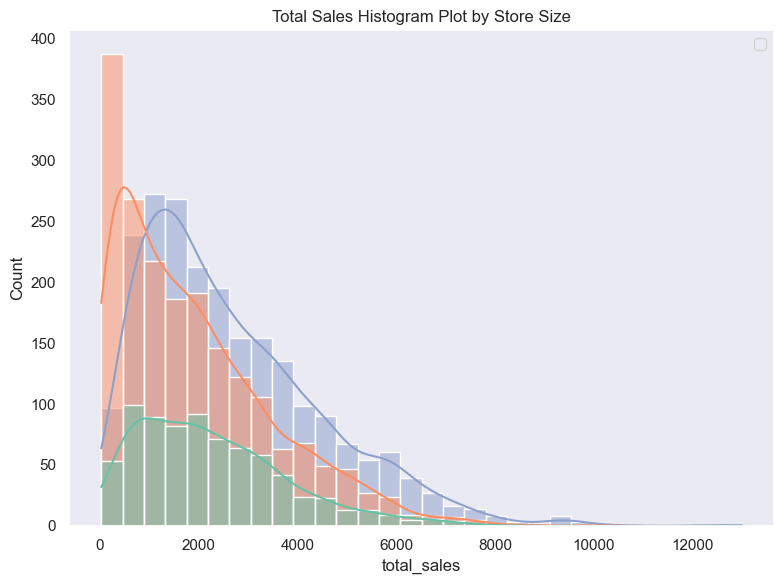

In [554]:
plt.figure(figsize=(8, 6))

sns.histplot(data=df, x='total_sales', hue='store_size',
              kde=True, palette='Set2', bins=30)
plt.title('Total Sales Histogram Plot by Store Size')
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

In [555]:
df['product_weight_kg'].describe().T

count    5593.000000
mean       12.850876
std         4.646542
min         4.482000
25%         8.750000
50%        12.647000
75%        16.894000
max        21.883000
Name: product_weight_kg, dtype: float64

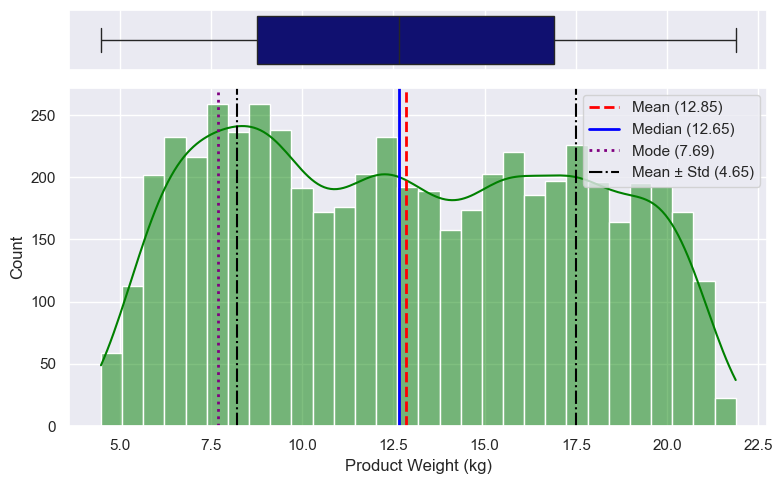

In [556]:
# How is product weight distributed?
# Calculate statistical metrics
mean_val = df["product_weight_kg"].mean()
median_val = df["product_weight_kg"].median()
mode_val = df["product_weight_kg"].mode()[0] 
std_val = df["product_weight_kg"].std()

# Create the plot structure
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, sharex=True, gridspec_kw={"height_ratios": (0.15, 0.85)}, 
    figsize=(8, 5))

sns.boxplot(data=df, x="product_weight_kg", 
            ax=ax_box, color="Navy")
ax_box.set(xlabel="")

sns.histplot(
    data=df, x="product_weight_kg", ax=ax_hist, 
    color="green", kde=True, bins=30)
ax_hist.set(xlabel="Product Weight (kg)")

# Add vertical lines for Mean, Median, Mode, and Std Bounds
ax_hist.axvline(
    mean_val,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean ({mean_val:.2f})",
)
ax_hist.axvline(
    median_val,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Median ({median_val:.2f})",
)
ax_hist.axvline(
    mode_val,
    color="purple",
    linestyle=":",
    linewidth=2,
    label=f"Mode ({mode_val:.2f})",
)

# Standard deviation lines (Mean ± 1 Std Dev)
ax_hist.axvline(
    mean_val - std_val,
    color="black",
    linestyle="-.",
    linewidth=1.5,
    label=f"Mean ± Std ({std_val:.2f})",
)
ax_hist.axvline(mean_val + std_val, color="black", linestyle="-.", linewidth=1.5)

ax_hist.legend()
plt.tight_layout()
plt.show()

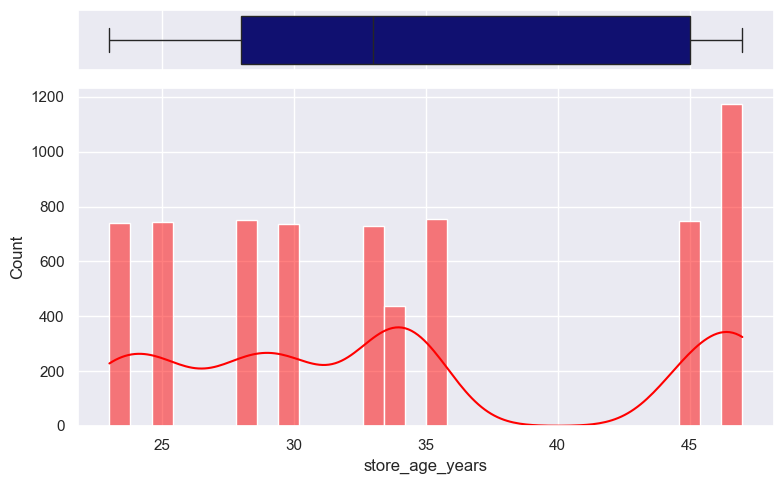

In [557]:
# Store Age

fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, sharex=True, gridspec_kw={'height_ratios':(0.15, 0.85)}, figsize=(8, 5)
)

sns.boxplot(data=df, x='store_age_years', ax=ax_box, color='Navy')
ax_box.set(xlabel='Store Age')

sns.histplot(data=df, x='store_age_years', ax=ax_hist,color='red', kde=True, bins=30)
plt.tight_layout()
plt.show()

From the above series of analysis, only the target variable (total sales) contain outliers. 

## EXPLORATORY DATA ANALYSIS

Bivariate Analysis

In [558]:
df.columns

Index(['id', 'product_code', 'product_weight_kg', 'fat_content',
       'shelf_visibility', 'product_category', 'product_price', 'store_code',
       'store_age_years', 'store_size', 'store_location_tier', 'store_format',
       'total_sales'],
      dtype='object')

In [559]:
# Does fat content affect total sales?
df_byfat = df.groupby('fat_content')['total_sales']
df_byfat.agg(['mean', 'std'])

,mean,std
fat_content,,
Low Fat,2151.165785,1692.633895
Regular,2218.379323,1707.076497


In [560]:
# Total sales by product category

df_by_product = df.groupby('product_category')['total_sales'].sum()
df_by_product

product_category
Baking goods             1002803.10
Breads                    456905.95
Breakfast                 157436.81
Canned                   1135538.15
Dairy                    1240027.66
Frozen foods             1445019.84
Fruits and vegetables    2291521.80
Hard drinks               370063.22
Health and hygiene        822461.61
Household                1696423.85
Meat                      767601.22
Others                    257061.53
Seafood                   117651.26
Snack foods              2074833.92
Soft drinks               720068.20
Starchy foods             272072.20
Name: total_sales, dtype: float64

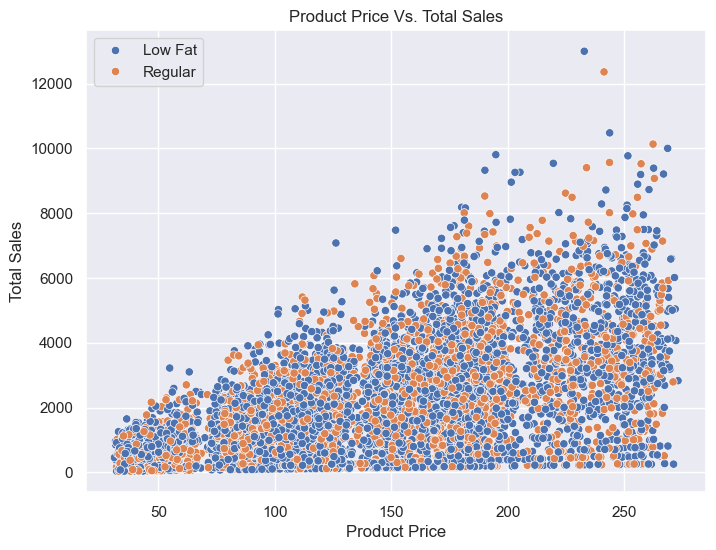

In [561]:
# How does product price drives the total sales

plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x='product_price', y='total_sales', hue='fat_content')

plt.title('Product Price Vs. Total Sales')
plt.xlabel('Product Price')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

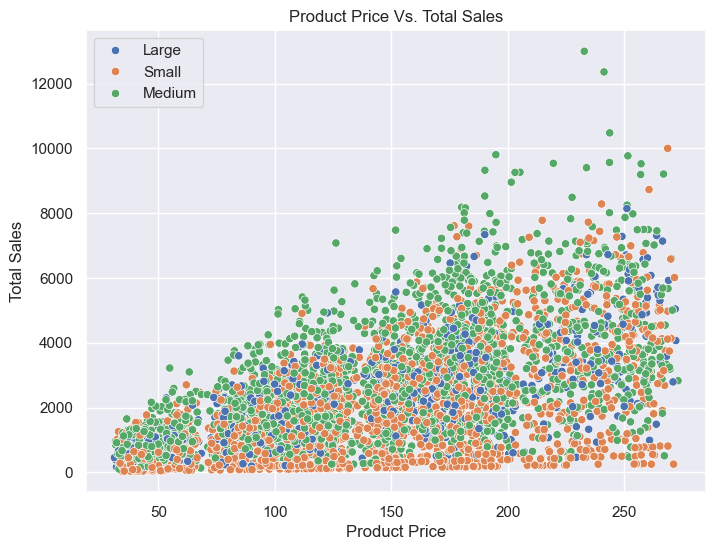

In [562]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x='product_price', y='total_sales', hue='store_size')

plt.title('Product Price Vs. Total Sales')
plt.xlabel('Product Price')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

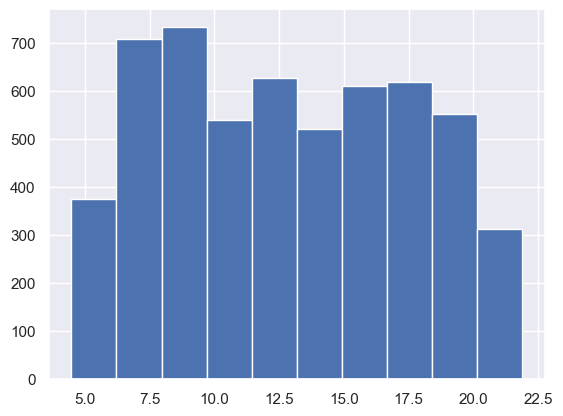

In [563]:
df['product_weight_kg'].hist()
plt.show()

In [564]:
df_copy = df.copy()

Handling Missing Data

In [565]:
# Filling the missing product weight with the meddian by product category
product_cat_median = df_copy.groupby("product_category")['product_weight_kg'].median()

for i, v in product_cat_median.sort_values().items():
    print(f"{i:<30} {v:.2f} kg")

Hard drinks                    9.57 kg
Breads                         10.56 kg
Breakfast                      10.99 kg
Baking goods                   11.50 kg
Soft drinks                    11.57 kg
Seafood                        11.81 kg
Health and hygiene             12.06 kg
Canned                         12.24 kg
Meat                           12.38 kg
Frozen foods                   12.81 kg
Snack foods                    13.08 kg
Fruits and vegetables          13.09 kg
Starchy foods                  13.19 kg
Dairy                          13.36 kg
Household                      13.37 kg
Others                         14.55 kg


In [566]:
for v in df_copy["product_category"].unique():
    weight = product_cat_median.get(v, df_copy["product_weight_kg"].median())
    df_copy.loc[(df_copy["product_category"]==v) & (df_copy["product_weight_kg"].isna()), 
                "product_weight_kg"] = weight
   

In [567]:
df_copy["product_weight_kg"].isna().sum()

np.int64(0)

No more missing value in column "Product Weight by Kg"

In [568]:
# Inspecting the store size column
df_copy['store_size'].value_counts(dropna=False)

store_size
Medium    2218
Small     1933
NaN       1919
Large      748
Name: count, dtype: int64

To fill the missing store_size, we need to inspect the relationship of Store Size column and some other columns

In [569]:
df_copy.groupby('store_code')['store_size'].apply(lambda x:x.value_counts(dropna=False)).T

store_code        
STORE-7WS   Medium    748
STORE-89Z   Medium    728
STORE-9RG   Small     752
STORE-AGY   Large     748
STORE-DKU   NaN       736
STORE-HL7   Medium    742
STORE-JOR   NaN       439
STORE-OYG   NaN       744
STORE-T5G   Small     427
STORE-YLW   Small     754
Name: store_size, dtype: int64

In [570]:
# Available store_code with matching store_size
store_size_code = df_copy.dropna(subset=["store_size"]).groupby("store_code")["store_size"].first()
print(store_size_code)

store_code
STORE-7WS    Medium
STORE-89Z    Medium
STORE-9RG     Small
STORE-AGY     Large
STORE-HL7    Medium
STORE-T5G     Small
STORE-YLW     Small
Name: store_size, dtype: object


- The rows with missing store size are just three which means, they cannot be mapped from the available store_code. 
- Lets verify this in the next cell

In [571]:
# Filling the missing store_size datapoints in both train and test columns

df_copy["store_size"] = df_copy["store_code"].map(store_size_code).fillna(df_copy["store_size"])


print(f"After fillna, Train-set Store_size column missing data : {df_copy["store_size"].isna().sum()}")

After fillna, Train-set Store_size column missing data : 1919


Further checking of the store_size column with other properties using crosstab

In [572]:
pd.crosstab(df_copy['store_location_tier'], df_copy['store_size'],
            normalize='index')

store_size,Large,Medium,Small
store_location_tier,,,
Tier_1,0.000000,0.381351,0.618649
Tier_2,0.000000,0.000000,1.000000
Tier_3,0.334227,0.665773,0.000000


The cross tab tells us that:

- Tier 2 location has 100% small store size
- Tier 1 has medium or small size
- Tier 3 has large or medium size store

More important thing to notice is that; only tier 3 has Large store size

In [573]:
pd.crosstab(df_copy['store_format'], df_copy['store_size'],
            normalize='index')

store_size,Large,Medium,Small
store_format,,,
Corner Shop,0.000000,0.000000,1.00000
Flagship Hypermarket,0.000000,1.000000,0.00000
Standard Supermarket,0.250838,0.244131,0.50503
Superstore,0.000000,1.000000,0.00000


Comparison of the store format with store size reveals some important information
- Corner shop is 100% small
- All Flagship Hypermarket are medium sized stores 
- All Superstore are also medium sized stores
- While standard supermarket has 50% small, 25% large and 25% medium sized

In [574]:
pd.crosstab([df_copy['store_location_tier'], df_copy['store_format']],
            df_copy['store_size'], normalize='index')

store_size                                Large    Medium     Small
store_location_tier store_format                                   
Tier_1              Corner Shop             0.0  0.000000  1.000000
                    Standard Supermarket    0.0  0.491228  0.508772
Tier_2              Standard Supermarket    0.0  0.000000  1.000000
Tier_3              Flagship Hypermarket    0.0  1.000000  0.000000
                    Standard Supermarket    1.0  0.000000  0.000000
                    Superstore              0.0  1.000000  0.000000

The above crosstab between Storesize, store_format and store location tier tells us breif info:
- Tier1-Corner Shop : Small
- Tier2- Standard Supermarket : Small
- Tier3 - Standard Supermarket : Large
- Tier3 - Hypermarket : Medium
- Tier3-Superstore : Medium

In [575]:
pd.crosstab(df_copy['store_code'],
             df_copy['store_size'], dropna=False)

store_size,Large,Medium,Small,NaN
store_code,,,,
STORE-7WS,0,748,0,0
STORE-89Z,0,728,0,0
STORE-9RG,0,0,752,0
STORE-AGY,748,0,0,0
STORE-DKU,0,0,0,736
STORE-HL7,0,742,0,0
STORE-JOR,0,0,0,439
STORE-OYG,0,0,0,744
STORE-T5G,0,0,427,0


In [576]:
df_copy[df_copy['store_size'].isna()][
   [
   'store_code',
    'store_age_years',
    'store_location_tier',
    'store_format'
   ]].drop_duplicates()

,store_code,store_age_years,store_location_tier,store_format
9,STORE-JOR,34,Tier_3,Corner Shop
11,STORE-OYG,25,Tier_2,Standard Supermarket
14,STORE-DKU,30,Tier_2,Standard Supermarket


For the three stores:
- STORE-OYG & DKU: Tier2-Standard (Small)
- STORE-JOR : Tier3-Corner Shop ()

STOREs OYG and DKU will be filled with small, JOR with modal store size

In [577]:
df_copy["store_code"].unique()

array(['STORE-AGY', 'STORE-YLW', 'STORE-89Z', 'STORE-7WS', 'STORE-9RG',
       'STORE-HL7', 'STORE-JOR', 'STORE-T5G', 'STORE-OYG', 'STORE-DKU'],
      dtype=object)

# Now lets fill the missing datapoints of store_size
values = ["STORE-DKU", "STORE-OYG"]
for _ in df_copy["store_code"].unique():
    df_copy.loc[(df_copy["store_code"] == any(values)) & (df_copy["store_size"].isna()), "store_size"]="Small"
    df_copy.loc[(df_copy["store_code"] == "JOR") & (df_copy["store_size"].isna()), "store_size"]="Medium"


In [578]:
#df_copy["store_size"] = df_copy["store_size"].fillna(df_copy["store_size"].mode()[0])

# Mapping the store size based on our deduction
store_size_map = {"STORE-JOR":"Medium",
                  "STORE-OYG":"Small",
                  "STORE-DKU":"Small"}

df_copy["store_size"] = df_copy["store_size"].fillna(df_copy["store_code"].map(store_size_map))

df_copy.isna().sum()

id                     0
product_code           0
product_weight_kg      0
fat_content            0
shelf_visibility       0
product_category       0
product_price          0
store_code             0
store_age_years        0
store_size             0
store_location_tier    0
store_format           0
total_sales            0
dtype: int64

In [579]:
# Relationship with storesize
df_by_store_size = df_copy.groupby("store_size")["total_sales"].agg(["mean", "median"])
df_by_store_size

,mean,median
store_size,,
Large,2254.890120,1998.725
Medium,2284.531844,1799.560
Small,2071.734955,1748.940


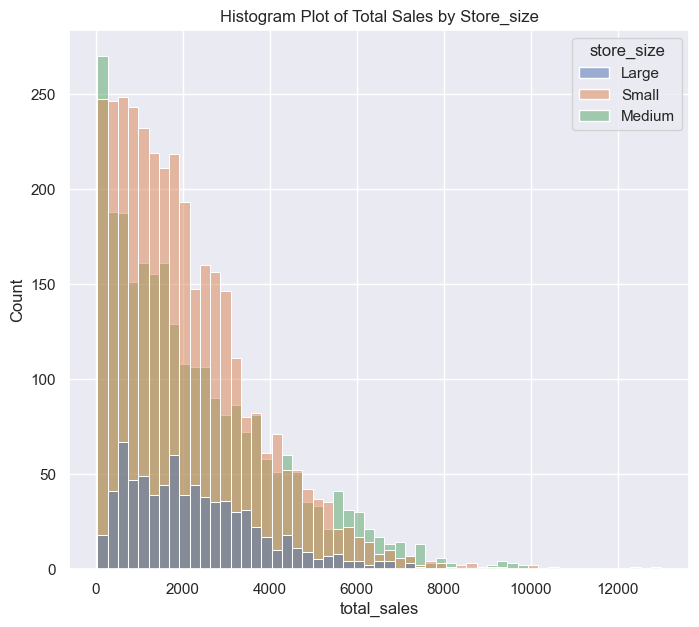

In [580]:
plt.figure(figsize=(8, 7))
sns.histplot(df_copy, x="total_sales", hue="store_size")
plt.title("Histogram Plot of Total Sales by Store_size")
plt.show()

- Small size store sales more than medium and large
- While large size store make smaller sales.
There is need to explore the product price, store size and total sales relationship

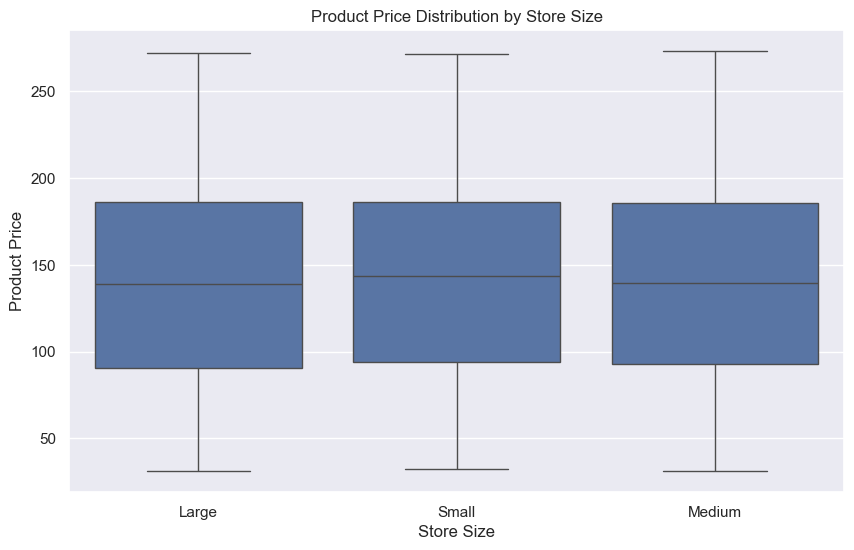

In [581]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_copy,
    x="store_size",
    y="product_price"
)

plt.title("Product Price Distribution by Store Size")
plt.xlabel("Store Size")
plt.ylabel("Product Price")

plt.show()

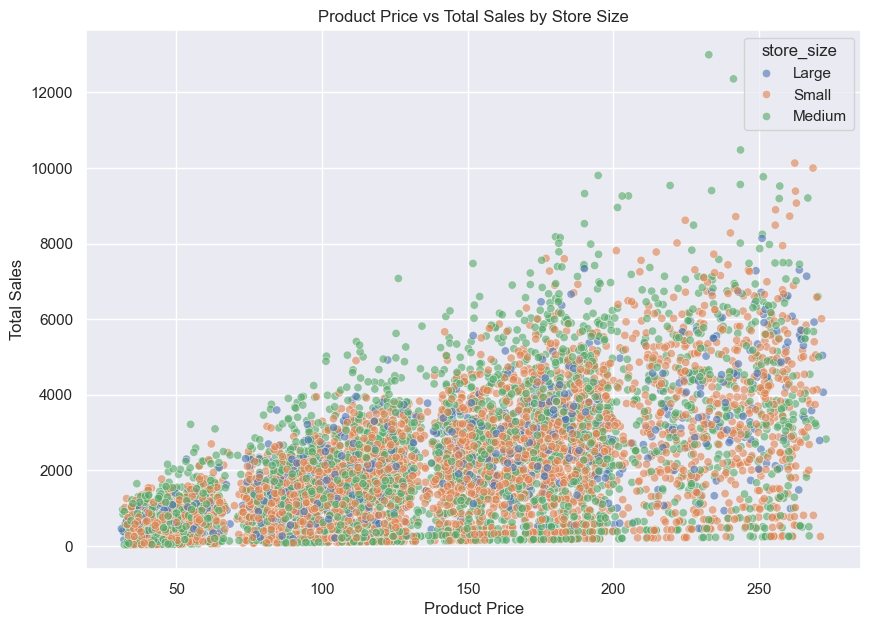

In [582]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_copy,
    x="product_price",
    y="total_sales",
    hue="store_size",
    alpha=0.6
)

plt.title("Product Price vs Total Sales by Store Size")
plt.xlabel("Product Price")
plt.ylabel("Total Sales")

plt.show()

In [583]:
price_sales_corr = (
    df_copy
    .groupby("store_size")
    .apply(
        lambda x: x["product_price"].corr(x["total_sales"]),
        include_groups=False
    )
)

price_sales_corr

store_size
Large     0.706163
Medium    0.533375
Small     0.585180
dtype: float64

In [584]:
df_copy["price_group"] = pd.qcut(df_copy["product_price"], q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"])

price_store_sales = (df_copy
    .groupby(["store_size", "price_group"], observed=True)["total_sales"]
    .agg(["mean", "median", "count"])
    .reset_index())

price_store_sales

,store_size,price_group,mean,median,count
0,Large,Very Low,820.035425,717.230,153
1,Large,Low,1614.260516,1567.420,155
2,Large,Medium,2265.835956,2232.540,136
3,Large,High,2936.766644,2948.600,146
4,Large,Very High,3633.293608,3399.955,158
5,Medium,Very Low,862.544101,751.665,534
6,Medium,Low,1645.118367,1554.180,539
7,Medium,Medium,2228.936866,2092.880,536
8,Medium,High,3024.674981,2933.740,526
9,Medium,Very High,3710.717548,3612.560,522


Treating the missing values in the test set

In [585]:
# Loading the test_data 
test = pd.read_csv('test.csv')
test.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format
0,row_00009,PRD-2WLNC8,8.628,Low Fat,0.0167,household,190.72,STORE-HL7,23,Medium,Tier_3,Superstore
1,row_00015,PRD-LV9PLM,6.993,Low Fat,0.0579,Health and Hygiene,261.07,STORE-9RG,28,Small,Tier_2,Standard Supermarket
2,row_00019,PRD-ET6ZI7,NaN,Low Fat,0.1262,FRUITS AND VEGETABLES,112.50,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket
3,row_00020,PRD-6RX35U,14.034,Regular,0.0761,frozen foods,200.71,STORE-DKU,30,NaN,Tier_2,Standard Supermarket
4,row_00023,PRD-I4J38V,13.063,Low Fat,0.0650,Frozen Foods,150.59,STORE-89Z,33,Medium,Tier_1,Standard Supermarket


In [586]:
print(f"Missing values before filling: \n{test.isna().sum()}")

Missing values before filling: 
id                       0
product_code             0
product_weight_kg      306
fat_content              0
shelf_visibility         0
product_category         0
product_price            0
store_code               0
store_age_years          0
store_size             491
store_location_tier      0
store_format             0
dtype: int64


In [587]:
test["store_size"] = test["store_size"].fillna(test["store_code"].map(store_size_map))
print(f"After fillna, Test-set Store_size column missing data : {test["store_size"].isna().sum()}")

After fillna, Test-set Store_size column missing data : 0


In [588]:
print(f"Missing values after filling: \n{test.isna().sum()}")

Missing values after filling: 
id                       0
product_code             0
product_weight_kg      306
fat_content              0
shelf_visibility         0
product_category         0
product_price            0
store_code               0
store_age_years          0
store_size               0
store_location_tier      0
store_format             0
dtype: int64


In [589]:
product_cat_median = test.groupby("product_category")['product_weight_kg'].median()

for v in test["product_category"].unique():
    weight = product_cat_median.get(v, test["product_weight_kg"].median())
    test.loc[(test["product_category"]==v) & (test["product_weight_kg"].isna()), "product_weight_kg"] = weight

In [590]:
print(f"Missing values after filling: \n{test.isna().sum()}")

Missing values after filling: 
id                     0
product_code           0
product_weight_kg      0
fat_content            0
shelf_visibility       0
product_category       0
product_price          0
store_code             0
store_age_years        0
store_size             0
store_location_tier    0
store_format           0
dtype: int64


In [591]:
df_copy.columns

Index(['id', 'product_code', 'product_weight_kg', 'fat_content',
       'shelf_visibility', 'product_category', 'product_price', 'store_code',
       'store_age_years', 'store_size', 'store_location_tier', 'store_format',
       'total_sales', 'price_group'],
      dtype='object')

## FEATURE ENGINEERING

In [592]:
# Creating more features
def new_features(data):
    
    data["price_per_kg"] = np.where(
        data["product_weight_kg"] > 0,
        data["product_price"] / data["product_weight_kg"],
        np.nan)

    data["price_visibility"] = (data["product_price"] * data["shelf_visibility"])

    data["weight_visibility"] = (data["product_weight_kg"] * data["shelf_visibility"])

    data["store_size_format"] = (data["store_size"].astype(str)
        + "_" + data["store_format"].astype(str))

    data["price_store_size"] = (
        data["store_size"].astype(str)
        + "_" + pd.cut(data["product_price"], bins=5, labels=["Very_Low", "Low", 
                                                              "Medium", "High", "Very_High"]).astype(str)    )

    data["category_fat"] = (
        data["product_category"].astype(str)
        + "_" + data["fat_content"].astype(str))

    return data


# Apply the engineering function
df_copy = new_features(df_copy)
test = new_features(test)

print(f"Train set now has {df_copy.shape[1]}")
print(f"Test set now has {test.shape[1]}")


Train set now has 20
Test set now has 18


In [593]:
# Rechecking missing data
df_copy.isna().sum()

id                     0
product_code           0
product_weight_kg      0
fat_content            0
shelf_visibility       0
product_category       0
product_price          0
store_code             0
store_age_years        0
store_size             0
store_location_tier    0
store_format           0
total_sales            0
price_group            0
price_per_kg           0
price_visibility       0
weight_visibility      0
store_size_format      0
price_store_size       0
category_fat           0
dtype: int64

In [594]:
test.isna().sum()

id                     0
product_code           0
product_weight_kg      0
fat_content            0
shelf_visibility       0
product_category       0
product_price          0
store_code             0
store_age_years        0
store_size             0
store_location_tier    0
store_format           0
price_per_kg           0
price_visibility       0
weight_visibility      0
store_size_format      0
price_store_size       0
category_fat           0
dtype: int64

### Categorical Feature Encoding 

In [595]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   id                   6818 non-null   object  
 1   product_code         6818 non-null   object  
 2   product_weight_kg    6818 non-null   float64 
 3   fat_content          6818 non-null   object  
 4   shelf_visibility     6818 non-null   float64 
 5   product_category     6818 non-null   object  
 6   product_price        6818 non-null   float64 
 7   store_code           6818 non-null   object  
 8   store_age_years      6818 non-null   int64   
 9   store_size           6818 non-null   object  
 10  store_location_tier  6818 non-null   object  
 11  store_format         6818 non-null   object  
 12  total_sales          6818 non-null   float64 
 13  price_group          6818 non-null   category
 14  price_per_kg         6818 non-null   float64 
 15  price_visibility     

In [596]:
df_copy.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales,price_group,price_per_kg,price_visibility,weight_visibility,store_size_format,price_store_size,category_fat
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98,Very Low,5.709374,2.205127,0.386229,Large_Standard Supermarket,Large_Low,Frozen foods_Low Fat
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,Health and hygiene,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13,Very Low,5.462458,3.027600,0.554256,Small_Standard Supermarket,Small_Very_Low,Health and hygiene_Low Fat
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85,Very Low,2.898906,1.740835,0.600514,Medium_Standard Supermarket,Medium_Very_Low,Canned_Regular
3,row_00003,PRD-UN5Z3J,11.571,Regular,0.0449,Soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72,High,15.067842,7.828315,0.519538,Medium_Flagship Hypermarket,Medium_Medium,Soft drinks_Regular
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,Meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36,Very High,19.642097,2.436720,0.124056,Small_Standard Supermarket,Small_High,Meat_Regular


### Modeling 

In [597]:
df_copy.columns

Index(['id', 'product_code', 'product_weight_kg', 'fat_content',
       'shelf_visibility', 'product_category', 'product_price', 'store_code',
       'store_age_years', 'store_size', 'store_location_tier', 'store_format',
       'total_sales', 'price_group', 'price_per_kg', 'price_visibility',
       'weight_visibility', 'store_size_format', 'price_store_size',
       'category_fat'],
      dtype='object')

Tranforming the target feature

In [598]:
df_copy['total_sales'].skew()

np.float64(1.1539947519138116)

In [599]:
df_copy['total_sales'].describe()

count     6818.000000
mean      2174.756574
std       1697.894956
min         32.700000
25%        834.792500
50%       1790.890000
75%       3092.587500
max      12996.820000
Name: total_sales, dtype: float64

In [600]:
sales_mean = df_copy['total_sales'].mean()
sales_median = df_copy['total_sales'].median()
sales_max = df_copy['total_sales'].max()
sales_min = df_copy['total_sales'].min()

print(f"Mean: {sales_mean}")
print(f"Median: {sales_median}")
print(f"Maximum: {sales_max}")
print(f"Minimum: {sales_min}")

Mean: 2174.7565737753007
Median: 1790.8899999999999
Maximum: 12996.82
Minimum: 32.7


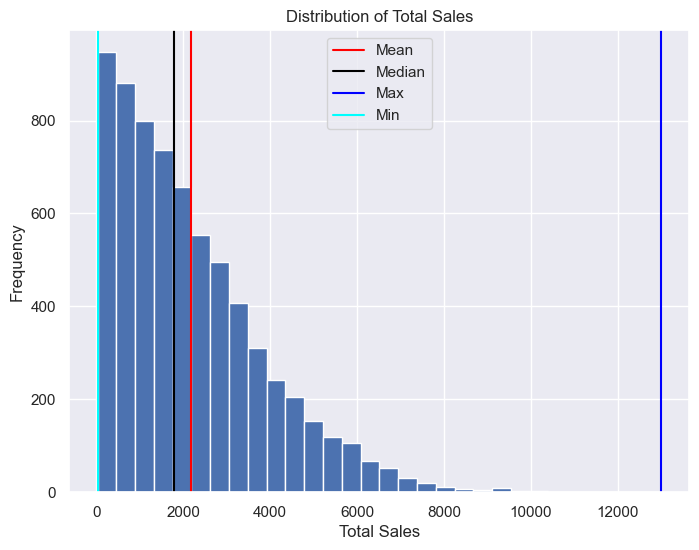

In [601]:
plt.figure(figsize=(8, 6))

plt.hist(df_copy['total_sales'], bins=30)
plt.title('Distribution of Total Sales')
plt.axvline(sales_mean, color = 'red', label='Mean')
plt.axvline(sales_median, color = 'black', label='Median')
plt.axvline(sales_max, color = 'blue', label='Max')
plt.axvline(sales_min, color = 'cyan', label='Min')
plt.legend()
plt.xlabel('Total Sales')
plt.ylabel('Frequency')
plt.show()

The above; mean:2174.75 and std:1697.89 shows that the target is right skew.
- Most of the customers purchase less than the average sales

# Horizontal splitting

In [602]:
df_copy.columns

Index(['id', 'product_code', 'product_weight_kg', 'fat_content',
       'shelf_visibility', 'product_category', 'product_price', 'store_code',
       'store_age_years', 'store_size', 'store_location_tier', 'store_format',
       'total_sales', 'price_group', 'price_per_kg', 'price_visibility',
       'weight_visibility', 'store_size_format', 'price_store_size',
       'category_fat'],
      dtype='object')

In [603]:
df_copy.shape[1]

20

In [604]:
cat_cols = df_copy.drop(["id", "product_code", "price_group"], 
                        axis=1).select_dtypes(include="object").columns.tolist()
cat_cols

['fat_content',
 'product_category',
 'store_code',
 'store_size',
 'store_location_tier',
 'store_format',
 'store_size_format',
 'price_store_size',
 'category_fat']

In [605]:
num_cols = df_copy.drop(["id", "product_code", "total_sales"], 
                        axis=1).select_dtypes(include=["float", "int"]).columns.tolist()
num_cols

['product_weight_kg',
 'shelf_visibility',
 'product_price',
 'store_age_years',
 'price_per_kg',
 'price_visibility',
 'weight_visibility']

In [606]:
set(df_copy.columns.to_list()) - set(num_cols + cat_cols)

{'id', 'price_group', 'product_code', 'total_sales'}

In [607]:
target = 'total_sales'

features = num_cols + cat_cols

x = df_copy[features]
y = df_copy[target]

print(x.shape)
print(y.shape)

(6818, 16)
(6818,)


In [608]:
set(df_copy.columns) - set(x.columns)

{'id', 'price_group', 'product_code', 'total_sales'}

In [609]:
x.head()

,product_weight_kg,shelf_visibility,product_price,store_age_years,price_per_kg,price_visibility,weight_visibility,fat_content,product_category,store_code,store_size,store_location_tier,store_format,store_size_format,price_store_size,category_fat
0,14.252,0.0271,81.37,45,5.709374,2.205127,0.386229,Low Fat,Frozen foods,STORE-AGY,Large,Tier_3,Standard Supermarket,Large_Standard Supermarket,Large_Low,Frozen foods_Low Fat
1,7.698,0.0720,42.05,35,5.462458,3.027600,0.554256,Low Fat,Health and hygiene,STORE-YLW,Small,Tier_1,Standard Supermarket,Small_Standard Supermarket,Small_Very_Low,Health and hygiene_Low Fat
2,14.264,0.0421,41.35,33,2.898906,1.740835,0.600514,Regular,Canned,STORE-89Z,Medium,Tier_1,Standard Supermarket,Medium_Standard Supermarket,Medium_Very_Low,Canned_Regular
3,11.571,0.0449,174.35,47,15.067842,7.828315,0.519538,Regular,Soft drinks,STORE-7WS,Medium,Tier_3,Flagship Hypermarket,Medium_Flagship Hypermarket,Medium_Medium,Soft drinks_Regular
4,10.338,0.0120,203.06,28,19.642097,2.436720,0.124056,Regular,Meat,STORE-9RG,Small,Tier_2,Standard Supermarket,Small_Standard Supermarket,Small_High,Meat_Regular


In [504]:
# Log transform of target
ylog = np.log1p(y)

In [610]:
# Creating model pipeline

preprocessor = ColumnTransformer(transformers=[
            ('imputer', SimpleImputer(strategy='median'), num_cols),

            ('cat', Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(
                    drop='first',
                    handle_unknown='ignore',
                    sparse_output=False))
            ]), cat_cols
        )])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.

In [611]:
# MODEL 1: LINEAR REGRESSION

lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', LinearRegression())
])

lr_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [612]:
# Train test split 
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=101)

print(f'Train_set Shape : {x_train.shape}, {y_train.shape}')
print(f'Test_set Shape : {x_test.shape}, {y_test.shape}')
print()


Train_set Shape : (5454, 16), (5454,)
Test_set Shape : (1364, 16), (1364,)



In [398]:
y_train_log = np.log1p(y_train)

In [613]:
# Fitting the model
lr_pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [614]:
# Prediction and evaluation

lr_pred = lr_pipeline.predict(x_test)

In [615]:
def eva(model, real, pred):
    mae = mean_absolute_error(real, pred)
    mse = mean_squared_error(real, pred)
    R2score = r2_score(real, pred)

    print(f"Model Evaluation of {model}")
    print("--"*20)
    print(f'MAE: {mae}')
    print(f'MSE: {mse}')
    print(f'RMSE: {np.sqrt(mse)}')
    print(f'R2Score: {R2score}')

In [616]:
# Evaluation

eva("LinearRegression", y_test, lr_pred)

Model Evaluation of LinearRegression
----------------------------------------
MAE: 849.5749694264983
MSE: 1343383.1965511607
RMSE: 1159.0440874061524
R2Score: 0.5373518770628551


In [617]:
# MODEL 2: RANDOMFOREST

rf_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', RandomForestRegressor())
])

rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [618]:
# Fitting the model

rf_pipeline.fit(x_train, y_train)
rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [619]:
rf_pred = rf_pipeline.predict(x_test)


In [620]:
mae_rf = mean_absolute_error(y_test, rf_pred)
mse_rf = mean_squared_error(y_test, rf_pred)
R2score_rf = r2_score(y_test, rf_pred)

print(f'MAE: {mae_rf}')
print(f'MSE: {mse_rf}')
print(f'RMSE: {np.sqrt(mse_rf)}')
print(f'R2Score: {R2score_rf}')

MAE: 794.0709659824047
MSE: 1332445.0443798236
RMSE: 1154.3158338946164
R2Score: 0.5411188704147607


In [621]:
# MODEL 3: XGBOOST
xgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', XGBRegressor(n_estimators=300, learning_rate=0.05,
    max_depth=6, random_state=42))
])

xgb_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [622]:
xgb_pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [623]:
xgb_pred = xgb_pipeline.predict(x_test)

In [624]:
mae_xgb = mean_absolute_error(y_test, xgb_pred)
mse_xgb = mean_squared_error(y_test, xgb_pred)
R2score_xgb = r2_score(y_test, xgb_pred)

print(f'MAE: {mae_xgb}')
print(f'MSE: {mse_xgb}')
print(f'RMSE: {np.sqrt(mse_xgb)}')
print(f'R2Score: {R2score_xgb}')

MAE: 795.4583713792705
MSE: 1341834.6848952211
RMSE: 1158.3758823867238
R2Score: 0.5378851694345372


In [519]:
lgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', LGBMRegressor())
])

lgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [520]:
lgb_pipeline.fit(x_train, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003380 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1923
[LightGBM] [Info] Number of data points in the train set: 5454, number of used features: 72
[LightGBM] [Info] Start training from score 2193.177571


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [521]:
lgb_pred=lgb_pipeline.predict(x_test)

In [522]:
mae_lgb = mean_absolute_error(y_test, lgb_pred)
mse_lgb = mean_squared_error(y_test, lgb_pred)
R2score_lgb = r2_score(y_test, lgb_pred)

print(f'MAE: {mae_lgb}')
print(f'MSE: {mse_lgb}')
print(f'RMSE: {np.sqrt(mse_lgb)}')
print(f'R2Score: {R2score_lgb}')

MAE: 788.3670473331816
MSE: 1317774.4202439499
RMSE: 1147.9435614366892
R2Score: 0.5461712908531013


Hyperparameter optimization

In [436]:
from sklearn.model_selection import RandomizedSearchCV

In [438]:
rf_pipeline.get_params().keys()

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'prep', 'reg', 'prep__force_int_remainder_cols', 'prep__n_jobs', 'prep__remainder', 'prep__sparse_threshold', 'prep__transformer_weights', 'prep__transformers', 'prep__verbose', 'prep__verbose_feature_names_out', 'prep__imputer', 'prep__cat', 'prep__imputer__add_indicator', 'prep__imputer__copy', 'prep__imputer__fill_value', 'prep__imputer__keep_empty_features', 'prep__imputer__missing_values', 'prep__imputer__strategy', 'prep__cat__memory', 'prep__cat__steps', 'prep__cat__transform_input', 'prep__cat__verbose', 'prep__cat__imputer', 'prep__cat__encoder', 'prep__cat__imputer__add_indicator', 'prep__cat__imputer__copy', 'prep__cat__imputer__fill_value', 'prep__cat__imputer__keep_empty_features', 'prep__cat__imputer__missing_values', 'prep__cat__imputer__strategy', 'prep__cat__encoder__categories', 'prep__cat__encoder__drop', 'prep__cat__encoder__dtype', 'prep__cat__encoder__feature_name_combiner', 'prep__cat__encoder__handle_un

In [439]:
# Random forest

param_grid = {
    'reg__n_estimators': [100, 200, 300, 500, 800],
    'reg__max_depth': [None, 10, 20, 30, 40, 50],
    'reg__min_samples_split': [2, 5, 10, 15],
    'reg__min_samples_leaf': [1, 2, 4, 8],
    'reg__max_features': ['sqrt', 'log2', 0.5, 0.8, 1.0],
    'reg__bootstrap': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'reg__bootstrap': [True, False], 'reg__max_depth': [None, 10, ...], 'reg__max_features': ['sqrt', 'log2', ...], 'reg__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-

In [441]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'reg__n_estimators': 300, 'reg__min_samples_split': 5, 'reg__min_samples_leaf': 4, 'reg__max_features': 'sqrt', 'reg__max_depth': 50, 'reg__bootstrap': True}

Best CV RMSE:
1071.714130088903


In [442]:
rf_best=random_search.best_estimator_

In [443]:
rf_pred2 = rf_best.predict(x_test)

In [444]:
eva("RandomForest_Tuned", y_test, rf_pred2)

Model Evaluation of RandomForest_Tuned
----------------------------------------
MAE: 769.5837828141902
MSE: 1235906.1344593419
RMSE: 1111.7131529577862
R2Score: 0.5743659331886384


In [523]:
# LightGBM Hyperparameter Tuning

param_grid = {
    'reg__n_estimators': [100, 200, 300, 500, 800],
    'reg__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'reg__max_depth': [-1, 5, 10, 15, 20],
    'reg__num_leaves': [15, 31, 50, 75, 100],
    'reg__min_child_samples': [10, 20, 30, 50],
    'reg__subsample': [0.7, 0.8, 0.9, 1.0],
    'reg__colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

random_search_lgbm = RandomizedSearchCV(
    estimator=lgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_lgbm.fit(x_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000450 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1911
[LightGBM] [Info] Number of data points in the train set: 5454, number of used features: 66
[LightGBM] [Info] Start training from score 2193.177571
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Ligh

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'reg__colsample_bytree': [0.7, 0.8, ...], 'reg__learning_rate': [0.01, 0.03, ...], 'reg__max_depth': [-1, 5, ...], 'reg__min_child_samples': [10, 20, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the various

In [524]:
print("Best Parameters:")
print(random_search_lgbm.best_params_)

best_cv_rmse = -random_search_lgbm.best_score_
print("Best CV RMSE:", best_cv_rmse)

Best Parameters:
{'reg__subsample': 0.8, 'reg__num_leaves': 50, 'reg__n_estimators': 500, 'reg__min_child_samples': 50, 'reg__max_depth': 5, 'reg__learning_rate': 0.01, 'reg__colsample_bytree': 0.7}
Best CV RMSE: 1072.0173554632836


In [526]:
lgb_best = random_search_lgbm.best_estimator_
lgb_pred2 = lgb_best.predict(x_test)

In [527]:
eva("LGB_TUNED", y_test, lgb_pred2)

Model Evaluation of LGB_TUNED
----------------------------------------
MAE: 765.5570408761462
MSE: 1227872.037375466
RMSE: 1108.0938757052427
R2Score: 0.5771327981791285


### Prediction with the test dataset

In [445]:
test.columns

Index(['id', 'product_code', 'product_weight_kg', 'fat_content',
       'shelf_visibility', 'product_category', 'product_price', 'store_code',
       'store_age_years', 'store_size', 'store_location_tier', 'store_format',
       'price_visibility', 'price_bin', 'weight_bin', 'visibility_price',
       'log_price', 'price_per_kg', 'weight_visibility', 'log_store_age',
       'visibility_per_price', 'store_size_format', 'category_fat'],
      dtype='object')

In [446]:
test.shape[1]

23

In [448]:
test = test[features]

In [449]:
test.shape[1]

21

In [453]:
# submission 2: rf_tuned
test_pred3 = rf_best.predict(test)

In [ ]:
#test_pred = rf_pipeline.predict(test)

In [452]:
#len(test_pred)

In [454]:
# Import submission file

submission = pd.read_csv('sample_submission.csv')
submission.head()

,id,total_sales
0,row_00009,2174.76
1,row_00015,2174.76
2,row_00019,2174.76
3,row_00020,2174.76
4,row_00023,2174.76


In [144]:
len(submission)

1705

In [455]:
submission['total_sales'] =test_pred3.round(2)

In [456]:
submission.head()

,id,total_sales
0,row_00009,2972.41
1,row_00015,4163.12
2,row_00019,3175.49
3,row_00020,2918.09
4,row_00023,2629.35


In [457]:
submission.columns

Index(['id', 'total_sales'], dtype='object')

In [458]:
submission.to_csv('submission03.csv', index=False)